In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import scipy.stats as stats

In [2]:
# Load Data
music_data = pd.read_csv("song_genres_mapped_Alia.csv")  # Replace with actual filename
weather_data = pd.read_csv("vancouverWeather.csv")  # Replace with actual filename

In [3]:
# Convert timestamps to datetime format
music_data['timestamp'] = pd.to_datetime(music_data['endTime'])
weather_data['timestamp'] = pd.to_datetime(weather_data['datetime'])

In [4]:
# Round timestamps to nearest hour for merging
music_data['timestamp'] = music_data['timestamp'].dt.round('h')
weather_data['timestamp'] = weather_data['timestamp'].dt.round('h')

In [5]:
# Merge Data on Timestamp
merged_data = pd.merge(music_data, weather_data, on='timestamp', how='inner')

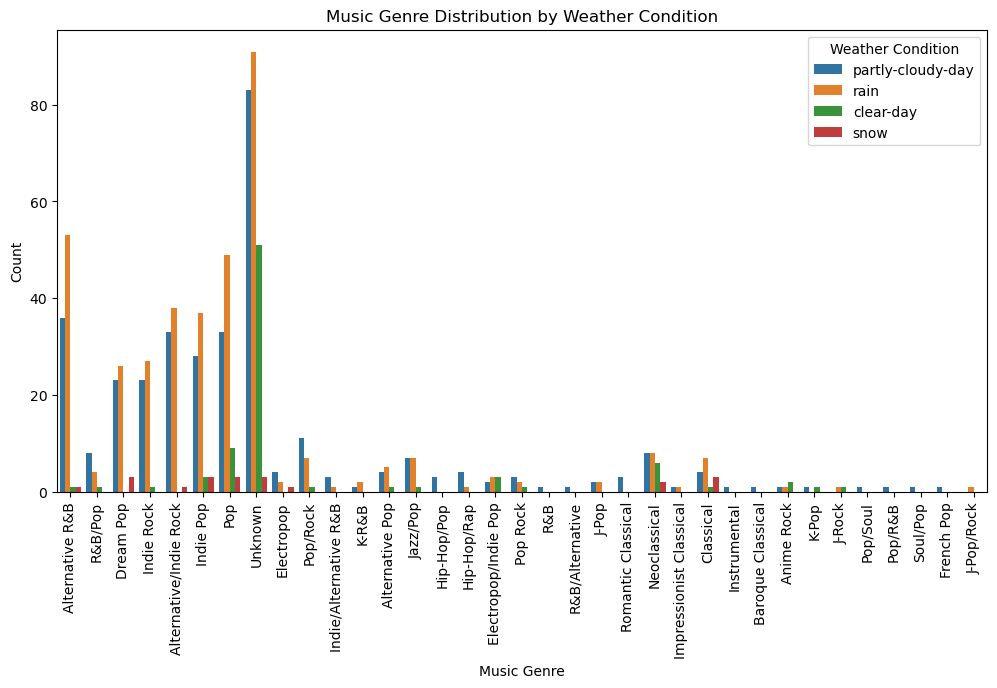

In [6]:
# Histogram: Genre Distribution by Weather Condition
plt.figure(figsize=(12, 6))
sns.countplot(data=merged_data, x='genre', hue='icon')
plt.title("Music Genre Distribution by Weather Condition")
plt.xticks(rotation=90)
plt.xlabel("Music Genre")
plt.ylabel("Count")
plt.legend(title="Weather Condition")
plt.show()

In [7]:
contingency_table = pd.crosstab(merged_data['icon'], merged_data['genre'])
chi2, p, dof, expected = stats.chi2_contingency(contingency_table)

print(f"Chi-Square Test Statistic: {chi2:.3f}")
print(f"P-Value: {p:.3f}")

if p < 0.05:
    print("There is a significant relationship between Weather Condition and Music Genre.")
else:
    print("No significant relationship found between Weather Condition and Music Genre.")

Chi-Square Test Statistic: 167.131
P-Value: 0.000
There is a significant relationship between Weather Condition and Music Genre.
